# ROMS Hawaiʻi reanalysis v2.0: virtual Icechunk smoke test (local)

A smoke test for the virtual Icechunk store planned in
[issue #11](https://github.com/ocean-icechunks/pacioos/issues/11): the PacIOOS ROMS reanalysis
for the main Hawaiian Islands (`roms_hiig_reanalysis`, v2.0), 3-hourly from 2009-01-01 to
2020-12-28, read from the unchanged NetCDF copies on Source Cooperative:

`https://data.source.coop/ocean-icechunks/pacioos/roms_hiig_reanalysis/netcdf/v2.0/<year>/hiig_his_zlevel_<YYYYMMDD>.nc`

The store will hold only Zarr metadata and byte-range references. No array data is copied, and
every read goes back to those files. The planned destination is
`ocean-icechunks/pacioos/roms_hiig_reanalysis/icechunk/`. **This notebook does not write
there.** It writes only to a temporary local directory, which it deletes at the end.

## What this notebook does

1. Checks that the copies serve byte ranges.
2. Inspects one file: formats, chunks, codecs and the metadata problems.
3. Checks that every sampled file has **the same internal layout**, byte for byte.
4. Takes the metadata repairs from PacIOOS's own ERDDAP record of the dataset, saved in
   `erddap_metadata.json`.
5. Builds **one depth plane per chunk** references inside the HDF5 chunks. This is the HYCOM
   trick, and it works because the HDF5 is uncompressed.
6. Writes four files across a year boundary to a local Icechunk repo (a write, then an
   append), reopens it read-only as a reader would, and checks structure and values against
   netCDF-C.
7. Builds a **whole year** (2009) from the shared layout and times the reads that matter:
   a map, and a 12-month point series.
8. Lists what is still unknown before the production build.

## Running it

It needs no credentials. It reads the public copies anonymously over HTTPS. It does not
need ERDDAP: the metadata come from the saved copy, and ERDDAP is only asked, if it answers,
whether anything has changed since. Run time is 2 to 3 minutes, most of it the netCDF-C reads
it checks against. Install with `pip install -r requirements.txt` in this folder (Python 3.12
or newer).

The build code is in `reanalysis_store.py`, beside this notebook, and is shared with the
scratch test and the production build. This notebook calls it and shows what it does.

**Decisions** (Eli Holmes, 2026-11-14, issue #11): one depth plane per chunk; metadata from
ERDDAP, with the title shortened; one group holding all five variables.

In [1]:
# Dependencies. In the git repo: pip install -r requirements.txt  (from this folder)
# That file includes ../requirements.txt, the shared list for stores/.
#
# icechunk 2.x requires Python >= 3.12. kerchunk and scipy are in the shared list for the
# NetCDF-3 products; the reanalysis is HDF5 and does not need them.

In [2]:
import sys
# pacioos_virtual.py (the shared reference helpers) lives one level up, in stores/.
sys.path.insert(0, '..')

import json
import shutil
import tempfile
import time
from pathlib import Path

import fsspec
import h5py
import icechunk
import matplotlib.pyplot as plt
import netCDF4
import numpy as np
import pandas as pd
import virtualizarr
import xarray as xr
import zarr

import pacioos_virtual as pv
import reanalysis_store as rs

# Local-filesystem storage logs a warning about concurrent commits on every open;
# this notebook commits from one process, so show errors only.
icechunk.set_logs_filter('error')

for name, mod in [('icechunk', icechunk), ('virtualizarr', virtualizarr), ('xarray', xr),
                  ('zarr', zarr), ('h5py', h5py), ('netCDF4', netCDF4), ('numpy', np)]:
    print(f'{name:13s}{mod.__version__}')
print(f'{"python":13s}{sys.version.split()[0]}')

icechunk     2.3.1
virtualizarr 2.8.0
xarray       2026.9.0
zarr         3.4.2
h5py         3.16.0
netCDF4      1.7.5.1.post1
numpy        2.5.4
python       3.12.12


**Tested environment.** Last run end to end on 2026-11-14, in a clean Python 3.12 venv
holding only `requirements.txt`: icechunk 2.3.1, virtualizarr 2.8.0, xarray 2026.9.0,
zarr 3.4.2, h5py 3.16.0, netCDF4 1.7.5. It took 2 to 3 minutes.

## 1. Configuration

`ZARR_CONCURRENCY` is recorded with every timing below. At Zarr's default of 10 the read
timings would measure the default setting, not the store.

In [3]:
# ------------------------------------------------------------------ source (the copies)
URL_PREFIX = rs.URL_PREFIX       # https://data.source.coop/ocean-icechunks/pacioos/
FILE_SIZE = rs.FILE_SIZE         # every one of the 4,380 copies is exactly this size
key = rs.key                     # day -> roms_hiig_reanalysis/netcdf/v2.0/<year>/<file>
ALL_DAYS = rs.ALL_DAYS           # 2009-01-01 .. 2020-12-28, daily
SCIENCE = rs.SCIENCE             # temp, salt, u, v, zeta
assert len(ALL_DAYS) == 4380

# ------------------------------------------------------------------ local scratch repo
WORK = Path(tempfile.mkdtemp(prefix='pacioos-reanalysis-smoke-'))

ZARR_CONCURRENCY = 128
zarr.config.set({'async.concurrency': ZARR_CONCURRENCY})

http = fsspec.filesystem('https')
print('files:   ', URL_PREFIX + key(ALL_DAYS[0]))
print('         ', f'... {len(ALL_DAYS)} daily files to', key(ALL_DAYS[-1]).rsplit('/', 1)[1])
print('work dir:', WORK)

files:    https://data.source.coop/ocean-icechunks/pacioos/roms_hiig_reanalysis/netcdf/v2.0/2009/hiig_his_zlevel_20090101.nc
          ... 4380 daily files to hiig_his_zlevel_20201228.nc
work dir: /tmp/pacioos-reanalysis-smoke-7cnomr_0


## 2. Byte-range access

A virtual store is only usable if the host answers ranged GETs with `206` and the right bytes.
The first 8 bytes of an HDF5 file are its signature.

In [4]:
import urllib.request

req = urllib.request.Request(URL_PREFIX + key(ALL_DAYS[0]), headers={'Range': 'bytes=0-7'})
with urllib.request.urlopen(req) as r:
    status, body = r.status, r.read()
    print('status       ', status)
    print('content-range', r.headers.get('Content-Range'))
    print('first bytes  ', body)

assert status == 206, 'the host did not honour the range request'
assert body == b'\x89HDF\r\n\x1a\n', 'not an HDF5 file'

status        206
content-range bytes 0-7/267070520
first bytes   b'\x89HDF\r\n\x1a\n'


## 3. One file, inspected

`pv.scan_h5` reads the header with h5py over HTTPS and returns, per variable, the shape,
dtype, chunk shape and attributes, plus the byte offset of every native chunk. It asserts
that nothing is compressed or shuffled, so a scan that returns at all has already shown that.

In [5]:
t0 = time.perf_counter()
s0 = pv.scan_h5(key(ALL_DAYS[0]))
print(f'scanned {s0["key"]} in {time.perf_counter() - t0:.1f}s\n')

rows = []
for name, v in s0['vars'].items():
    rows.append({'variable': name, 'shape': v['shape'], 'dtype': v['dtype'],
                 'chunks': v['chunk'] or 'contiguous',
                 'native chunks': len(v['offsets']) if 'offsets' in v else '',
                 'attributes': {k: a for k, a in v['attrs'].items()}})
print(pd.DataFrame(rows).to_string(index=False))
print('\ntime:', s0['time'][0], '...', s0['time'][-1], f'({len(s0["time"])} steps)')

scanned roms_hiig_reanalysis/netcdf/v2.0/2009/hiig_his_zlevel_20090101.nc in 0.6s

variable             shape dtype            chunks native chunks                                                                             attributes
     lat            (195,)   <f4        contiguous                                                  {'long_name': 'Latitude', 'units': 'degrees_north'}
     lon            (295,)   <f4        contiguous                                                  {'long_name': 'Longitude', 'units': 'degrees_east'}
   depth             (36,)   <f4        contiguous                                 {'long_name': 'Z-Level Depth', 'units': 'meter', 'positive': 'down'}
    mask        (195, 295)   <i2        contiguous                                              {'long_name': 'field mask', 'value': '0-land, 1-water'}
    time              (8,)   <f4           (1024,)               {'long_name': 'time since initialization', 'units': 'hours since 2000-01-01 00:00:00'}
    z

In [6]:
# The HDF5 chunks of one variable sit exactly one raw chunk apart: each chunk is
# 36 depth planes, back to back, uncompressed and in C order.
PLANE = rs.PLANE                           # one (lat, lon) float32 plane: 230,100 bytes
for name in ('temp', 'salt', 'u', 'v', 'zeta'):
    v = s0['vars'][name]
    nz = v['shape'][1] if len(v['shape']) == 4 else 1
    gaps = np.diff(v['offsets'].astype('int64'))
    assert (v['nbytes'] == nz * PLANE).all()
    print(f'{name:5s} chunk {v["chunk"]}  {int(v["nbytes"][0]):>9,} bytes = {nz:2d} planes'
          f' x {PLANE:,};  chunk spacing {sorted(set(gaps.tolist()))}')

temp  chunk (1, 36, 195, 295)  8,283,600 bytes = 36 planes x 230,100;  chunk spacing [8283600]
salt  chunk (1, 36, 195, 295)  8,283,600 bytes = 36 planes x 230,100;  chunk spacing [8283600]
u     chunk (1, 36, 195, 295)  8,283,600 bytes = 36 planes x 230,100;  chunk spacing [16567200]
v     chunk (1, 36, 195, 295)  8,283,600 bytes = 36 planes x 230,100;  chunk spacing [16567200]
zeta  chunk (1, 195, 295)    230,100 bytes =  1 planes x 230,100;  chunk spacing [230100]


What the scan shows, and what the store has to repair:

- **No `_FillValue` or `missing_value`** on any science variable. Land holds netCDF's default
  float fill, `9.96921e36`. A reader masks it only if the store declares it.
- `temp` has **`units = "ppt"`**, which is wrong (it is potential temperature, °C), and `salt`
  has **no units**.
- The only global attributes are `author`, `history` and `title = "Zlevel Model Data"`.
- `time` is `float32` hours since 2000-01-01. It is exact for these 3-hourly values.

## 4. Is the layout the same in every file?

All 4,380 copies are the same size. If their internal layouts are identical too, then one
header gives the references for every file, and the production scan becomes a confirmation,
not a dependency. This samples files on both sides of every boundary that could plausibly
change something: the first and last files, both year boundaries of 2009/2010, the 2012 leap
day, and one mid-year file in each year.

In [7]:
SAMPLE_DAYS = sorted(set(pd.to_datetime(
    ['2009-01-01', '2009-12-31', '2010-01-01', '2012-02-28', '2012-02-29', '2012-03-01',
     '2020-12-27', '2020-12-28'] + [f'{y}-07-01' for y in range(2009, 2021)])))

t0 = time.perf_counter()
layout = []
for day in SAMPLE_DAYS:
    k = key(day)
    size = http.info(URL_PREFIX + k)['size']
    s = s0 if day == ALL_DAYS[0] else pv.scan_h5(k)
    same_offsets = all(np.array_equal(s['vars'][n]['offsets'], s0['vars'][n]['offsets'])
                       and np.array_equal(s['vars'][n]['nbytes'], s0['vars'][n]['nbytes'])
                       for n in SCIENCE)
    same_coords = all(np.array_equal(s['coords'][c], s0['coords'][c])
                      for c in ('lat', 'lon', 'depth', 'mask'))
    expected_t = day + pd.to_timedelta(np.arange(8) * 3, 'h')
    layout.append({'file': k.rsplit('/', 1)[1], 'size': size, 'same offsets': same_offsets,
                   'same coords+mask': same_coords,
                   'times = day 00..21Z': bool((s['time'] == expected_t).all())})
layout = pd.DataFrame(layout)
print(layout.to_string(index=False))
print(f'\n{len(layout)} files scanned in {time.perf_counter() - t0:.0f}s')

assert (layout['size'] == FILE_SIZE).all()
assert layout[['same offsets', 'same coords+mask', 'times = day 00..21Z']].all().all()

                       file      size  same offsets  same coords+mask  times = day 00..21Z
hiig_his_zlevel_20090101.nc 267070520          True              True                 True
hiig_his_zlevel_20090701.nc 267070520          True              True                 True
hiig_his_zlevel_20091231.nc 267070520          True              True                 True
hiig_his_zlevel_20100101.nc 267070520          True              True                 True
hiig_his_zlevel_20100701.nc 267070520          True              True                 True
hiig_his_zlevel_20110701.nc 267070520          True              True                 True
hiig_his_zlevel_20120228.nc 267070520          True              True                 True
hiig_his_zlevel_20120229.nc 267070520          True              True                 True
hiig_his_zlevel_20120301.nc 267070520          True              True                 True
hiig_his_zlevel_20120701.nc 267070520          True              True                 True

## 5. Metadata from PacIOOS's ERDDAP, saved in the repository

The repairs need a source PacIOOS has published, not values chosen here. PacIOOS's ERDDAP
serves the same v2.0 reanalysis as two datasets, `roms_hiig_reanalysis` (temp, salt, u, v) and
`roms_hiig_reanalysis_ssh` (zeta), with corrected attributes. The store takes, from ERDDAP:

- every science variable's `long_name`, `standard_name`, `units` and `_FillValue`;
- the CF attributes of the coordinates (ERDDAP calls them `latitude`/`longitude`; the store
  keeps the files' names `lat`/`lon`, as the forecast store does);
- the global attributes, apart from those that only drive ERDDAP's own displays, and apart
  from the coverage, which is computed from the store. The title drops ERDDAP's
  ": 3-D Variables", because this store also holds `zeta`.

`mask` keeps its attributes from the file; ERDDAP does not publish it.

**The build reads a saved copy, `erddap_metadata.json`, not ERDDAP itself.** ERDDAP restarts
now and then: on 2026-11-14 it answered 503 and then "Currently unknown datasetID" for about a
minute. The metadata rarely change (ERDDAP dates its last change to 2023-03-08, when v2
replaced v1), so the saved copy is the right input, and this cell asks ERDDAP only whether it
still agrees. `rs.save_erddap_metadata()` refreshes the copy; review its diff before
committing it.

In [8]:
main_attrs, ssh_attrs, fetched = rs.load_metadata()
print(f'saved ERDDAP metadata, fetched {fetched}')

diffs = rs.compare_with_live_erddap()          # None when ERDDAP does not answer
if diffs is not None:
    print('live ERDDAP:', 'no differences' if diffs.empty else '')
    if not diffs.empty:
        print(diffs.to_string(index=False))

VAR_ATTRS = rs.variable_attrs(main_attrs, ssh_attrs, s0['vars']['mask']['attrs'])

# The single fill value must be the one the files actually hold.
FILL = VAR_ATTRS['temp']['_FillValue']
assert all(VAR_ATTRS[n]['_FillValue'] == FILL for n in SCIENCE)
assert FILL == np.float32(netCDF4.default_fillvals['f4'])

# What the store changes, variable by variable: file value -> ERDDAP value.
changes = []
for name in SCIENCE + ['lat', 'lon', 'depth', 'time']:
    file_attrs = s0['vars'][name]['attrs']
    for k, new in VAR_ATTRS[name].items():
        old = file_attrs.get(k, '(none)')
        if str(old) != str(new):
            changes.append({'variable': name, 'attribute': k, 'file': old, 'store': new})
print()
print(pd.DataFrame(changes).to_string(index=False))

g = rs.global_attrs(main_attrs, ALL_DAYS)
print(f'\n{len(g)} global attributes; title: {g["title"]!r}; '
      f'product_version: {g["product_version"]}')

saved ERDDAP metadata, fetched 2026-11-14T00:19:42Z


live ERDDAP: no differences

variable     attribute                 file                                    store
    temp standard_name               (none)          sea_water_potential_temperature
    temp         units                  ppt                                  Celsius
    temp    _FillValue               (none)  9969209968386869046778552952102584320.0
    salt standard_name               (none)                       sea_water_salinity
    salt         units               (none)                                     1e-3
    salt    _FillValue               (none)  9969209968386869046778552952102584320.0
       u     long_name u-momentum component                     u-velocity component
       u standard_name               (none)              eastward_sea_water_velocity
       u    _FillValue               (none)  9969209968386869046778552952102584320.0
       v     long_name v-momentum component                     v-velocity component
       v standard_name              

## 6. Build the virtual dataset: one depth plane per chunk

`pv.best_assignment` lays the files' steps on one regular 3-hourly axis. The reanalysis has no
overlapping runs, so this only checks that the steps tile without gaps. `pv.manifest_variable`
then writes, for each step and depth, a reference to one 230,100-byte `(lat, lon)` plane:
`chunk_offset + k × 230,100` inside the native HDF5 chunk.

| Chunk | Bytes | One surface map | Point series, one depth, 12 years |
|---|---|---|---|
| native `(1, 36, 195, 295)` | 8.3 MB | 8.3 MB | about 290 GB |
| **`(1, 1, 195, 295)` per depth** | **230 KB** | **230 KB** | **about 8 GB** |

`rs.build_dataset` does this. Dtypes are declared native, with the byte order (little) in
the `bytes` codec, as in `pacioos_virtual.py`. `_FillValue` goes in two places, for different readers: the Zarr
array's `fill_value`, which Zarr returns for a chunk that has no reference, and the
`_FillValue` attribute, which is what xarray masks on. For Zarr v3, xarray keeps that
attribute base64-encoded and refuses a plain float when it opens the store
(`TypeError: Failed to decode fill_value`), so it is written in xarray's own encoding,
exactly as `to_zarr` would write it.

In [9]:
def build_dataset(scans):
    return rs.build_dataset(scans, VAR_ATTRS, main_attrs)


SMALL_DAYS = pd.date_range('2009-12-30', '2010-01-02', freq='D')   # crosses a year folder
t0 = time.perf_counter()
small_scans = [s for s in (pv.scan_h5(key(d)) for d in SMALL_DAYS)]
print(f'scanned {len(small_scans)} files in {time.perf_counter() - t0:.1f}s')

first = build_dataset(small_scans[:2])
temp = first['temp'].data
print('temp:', temp.shape, 'chunks', temp.metadata.chunks, '| codec', temp.metadata.codecs)
print('reference [time 0, depth 1]:', temp.manifest.dict()['0.1.0.0'])
print('native chunk 0 starts at   ', int(small_scans[0]['vars']['temp']['offsets'][0]),
      f'(+ {PLANE:,} = one plane in)')

scanned 4 files in 2.7s


temp: (16, 36, 195, 295) chunks (1, 1, 195, 295) | codec (BytesCodec(endian='little'),)
reference [time 0, depth 1]: {'path': 'https://data.source.coop/ocean-icechunks/pacioos/roms_hiig_reanalysis/netcdf/v2.0/2009/hiig_his_zlevel_20091230.nc', 'offset': 2214452, 'length': 230100}
native chunk 0 starts at    1984352 (+ 230,100 = one plane in)


## 7. Write a local repository: a write, then an append

The repository config names one virtual chunk container, `https://data.source.coop/ocean-icechunks/pacioos/`
(the trailing `/` is required), and `save_config()` stores it in the repo, so a reader can
discover it. Manifests split on `time`, every 2,920 steps (one year), as planned for production.

The first two files go in as a write, and the next two as an append along `time`, which
crosses into the 2010 folder. The commit is tagged `v2.0`, as the published store will be.

**An append rewrites the root attributes** with those of the appended dataset. The first run
of this notebook ended with `time_coverage_start` at the first appended day. So the appended
part carries the global attributes for the whole store's span. Production must do the same
(or set them once, after the last batch).

In [10]:
small_path = WORK / 'small'
repo = icechunk.Repository.create(
    icechunk.local_filesystem_storage(str(small_path)),
    config=rs.repository_config(),
    authorize_virtual_chunk_access=pv.reader_authorization(),
)
repo.save_config()

session = repo.writable_session('main')
first.vz.to_icechunk(session.store)
session.commit(f'{SMALL_DAYS[0]:%Y-%m-%d}..{SMALL_DAYS[1]:%Y-%m-%d}')

# A committed session is read-only: open a new one for the append. Only the
# time-dependent variables are appended; the coordinates and mask are already there.
session = repo.writable_session('main')
rest = build_dataset(small_scans[2:]).drop_vars(['depth', 'lat', 'lon', 'mask'])
rest.attrs = rs.global_attrs(main_attrs, pd.DatetimeIndex(np.concatenate([first.time.values,
                                                           rest.time.values])))
rest.vz.to_icechunk(session.store, append_dim='time')
snapshot = session.commit(f'append {SMALL_DAYS[2]:%Y-%m-%d}..{SMALL_DAYS[3]:%Y-%m-%d}')
repo.create_tag('v2.0', snapshot_id=snapshot)

for entry in repo.ancestry(branch='main'):
    print(entry.written_at.strftime('%H:%M:%S'), entry.message)
print('tags:', list(repo.list_tags()))

00:21:51 append 2010-01-01..2010-01-02
00:21:51 2009-12-30..2009-12-31
00:21:51 Repository initialized
tags: ['v2.0']


## 8. Reopen as a reader

A new `Repository.open` with nothing carried over from the writer: the virtual chunk
containers are read from the saved config, and each is authorized for anonymous HTTP, the
same way a reader of the published store will do it. Opened twice: decoded, as a reader sees
it, and raw (`mask_and_scale=False`), for byte comparisons.

In [11]:
def open_reader(path, ref='main', chunks={}, **kw):
    # rs.open_store: a new Repository.open, containers from the saved config, each
    # authorized for anonymous HTTP. chunks={} (dask) here; rs.open_store defaults to None.
    return rs.open_store(icechunk.local_filesystem_storage(str(path)), ref=ref,
                         chunks=chunks, **kw)


t0 = time.perf_counter()
ds = open_reader(small_path, ref='v2.0')
print(f'opened (tag v2.0) in {time.perf_counter() - t0:.2f}s')
print('virtual chunk containers in the saved config:',
      list(icechunk.Repository.open(icechunk.local_filesystem_storage(str(small_path)))
           .config.virtual_chunk_containers), '\n')
raw = open_reader(small_path, mask_and_scale=False)
ds

opened (tag v2.0) in 0.04s
virtual chunk containers in the saved config: ['https://data.source.coop/ocean-icechunks/pacioos/'] 



<xarray.Dataset> Size: 1GB
Dimensions:  (time: 32, lat: 195, lon: 295, depth: 36)
Coordinates:
  * time     (time) datetime64[ns] 256B 2009-12-30 ... 2010-01-02T21:00:00
  * lat      (lat) float32 780B 17.02 17.05 17.09 17.13 ... 23.91 23.95 23.98
  * lon      (lon) float32 1kB -163.8 -163.8 -163.8 ... -152.6 -152.6 -152.5
  * depth    (depth) float32 144B 0.25 1.0 2.0 5.0 ... 4.5e+03 5e+03 5.5e+03
Data variables:
    zeta     (time, lat, lon) float32 7MB dask.array<chunksize=(1, 195, 295), meta=np.ndarray>
    salt     (time, depth, lat, lon) float32 265MB dask.array<chunksize=(1, 1, 195, 295), meta=np.ndarray>
    v        (time, depth, lat, lon) float32 265MB dask.array<chunksize=(1, 1, 195, 295), meta=np.ndarray>
    mask     (lat, lon) int16 115kB dask.array<chunksize=(195, 295), meta=np.ndarray>
    u        (time, depth, lat, lon) float32 265MB dask.array<chunksize=(1, 1, 195, 295), meta=np.ndarray>
    temp     (time, depth, lat, lon) float32 265MB dask.array<chunksize=(1, 1, 195, 295), meta=np.ndarray>
Attributes: (12/54)
    acknowledgement:            The Pacific Islands Ocean Observing System (P...
    comment:                    Model runs produced by Brian Powell (powellb@...
    Conventions:                CF-1.6, ACDD-1.3
    creator_email:              powellb@hawaii.edu
    creator_institution:        University of Hawaii at Manoa
    creator_name:               Brian S. Powell
    ...                         ...
    summary:                    Regional Ocean Modeling System (ROMS) 3-hourl...
    time_coverage_resolution:   PT3H
    title:                      Regional Ocean Modeling System (ROMS): Main H...
    time_coverage_start:        2009-12-30T00:00:00Z
    time_coverage_end:          2010-01-02T21:00:00Z
    source_files:               https://data.source.coop/ocean-icechunks/paci...

## 9. Structure

In [12]:
# The full axis: 35,040 3-hourly steps, 2009-01-01 to 2020-12-28T21Z, the same
# count and span ERDDAP lists (checked against ERDDAP's own axis on 2026-11-13).
assert len(rs.STEPS) == 35040

assert dict(ds.sizes) == {'time': 32, 'depth': 36, 'lat': 195, 'lon': 295}
assert set(ds.data_vars) == set(SCIENCE) | {'mask'}
t = pd.DatetimeIndex(ds.time.values)
assert t[0] == SMALL_DAYS[0] and (np.diff(t) == np.timedelta64(3, 'h')).all()
assert t.isin(rs.STEPS).all(), 'a step off the full axis'
for name in SCIENCE:
    enc = ds[name].encoding
    assert enc['chunks'] == ((1, 1, 195, 295) if name != 'zeta' else (1, 195, 295)), name
    assert enc['dtype'] == np.dtype('<f4') and enc['compressors'] == ()
    assert ds[name].attrs['units'] == VAR_ATTRS[name]['units']
assert ds.temp.attrs['units'] == 'Celsius' and ds.salt.attrs['units'] == '1e-3'
assert ds.attrs['product_version'] == '2.0'
assert (ds.attrs['time_coverage_start'], ds.attrs['time_coverage_end']) == (
    '2009-12-30T00:00:00Z', '2010-01-02T21:00:00Z'), 'the append overwrote the coverage'

for name in SCIENCE:
    print(f'{name:5s} {str(ds[name].dims):30s} chunks {ds[name].encoding["chunks"]}  '
          f'units {ds[name].attrs["units"]!r:16s} {ds[name].attrs["standard_name"]}')
print(f'\ntime: {t[0]} .. {t[-1]}, {len(t)} steps, all on the full 35,040-step axis')
print('structure checks passed')

temp  ('time', 'depth', 'lat', 'lon') chunks (1, 1, 195, 295)  units 'Celsius'        sea_water_potential_temperature
salt  ('time', 'depth', 'lat', 'lon') chunks (1, 1, 195, 295)  units '1e-3'           sea_water_salinity
u     ('time', 'depth', 'lat', 'lon') chunks (1, 1, 195, 295)  units 'meter second-1' eastward_sea_water_velocity
v     ('time', 'depth', 'lat', 'lon') chunks (1, 1, 195, 295)  units 'meter second-1' northward_sea_water_velocity
zeta  ('time', 'lat', 'lon')         chunks (1, 195, 295)  units 'meter'          sea_surface_height

time: 2009-12-30 00:00:00 .. 2010-01-02 21:00:00, 32 steps, all on the full 35,040-step axis
structure checks passed


## 10. Values against netCDF-C

The store holds no data, so "correct" means a read through a reference returns what the file
holds at that place. Each file is opened with netCDF-C over HTTPS byte ranges
(`#mode=bytes`), which is an independent reader. Compared at the first and last step of each
file, and at the surface, a middle level and the deepest level, for all five variables.

In [13]:
t0 = time.perf_counter()
checked, mismatches = 0, []
for f, day in enumerate(SMALL_DAYS):
    with netCDF4.Dataset(URL_PREFIX + key(day) + '#mode=bytes') as nc:
        for name in SCIENCE:
            v = nc[name]
            v.set_auto_maskandscale(False)
            for lead in (0, 7):
                i = 8 * f + lead
                for k in ((0, 20, 35) if name != 'zeta' else (None,)):
                    exp = v[lead] if k is None else v[lead, k]
                    got = (raw[name].isel(time=i) if k is None
                           else raw[name].isel(time=i, depth=k)).values
                    checked += 1
                    if not np.array_equal(got, exp):
                        mismatches.append((day.date(), name, lead, k))
print(f'{checked} planes compared in {time.perf_counter() - t0:.0f}s, mismatches: {mismatches}')
assert not mismatches

104 planes compared in 46s, mismatches: []


In [14]:
# Decoding: land must read as NaN, and only land. At the surface that is the
# 1,118 cells where mask == 0; deeper levels have more.
land = int((ds.mask.values == 0).sum())
surface = ds.temp.isel(time=0, depth=0).values
deep = raw.temp.isel(time=0, depth=35).values
assert int(np.isnan(surface).sum()) == land == 1118
assert np.array_equal(np.isnan(ds.temp.isel(time=0, depth=35).values), deep == FILL)
print(f'surface: {land} land cells (mask == 0) read as NaN; '
      f'5,500 m: {int((deep == FILL).sum())} fill cells read as NaN')
print(f'surface temp {np.nanmin(surface):.2f} .. {np.nanmax(surface):.2f} '
      f'{ds.temp.attrs["units"]}')

surface: 1118 land cells (mask == 0) read as NaN; 5,500 m: 57314 fill cells read as NaN
surface temp 23.51 .. 26.51 Celsius


## 11. A whole year from the shared layout, and timings

Section 4 found the same offsets in every sampled file, so here the references for all 365
files of 2009 are computed from the header of one file, by changing only the path and the
times. **That is a test of the layout, not the production method.** The production build
scans every file (issue #11, step 1). Eight steps from files that were *not* scanned are then
compared with netCDF-C, which tests the shared-layout claim on files the scan never saw.

The timings use the access patterns the reanalysis is for: one map, and a point time series at
one depth for a full year, 2,920 reads of 230 KB.

**Open the store without dask (`chunks=None`), or with large dask chunks, for a point
series.** With `chunks={}`, dask gets one task per 230 KB chunk, and its thread pool, not
Zarr's `async.concurrency`, limits how many reads are in flight. In the first run of this
notebook the year-long series below took **120 s (6 MB/s)** that way. With `chunks=None`,
Zarr issues all 2,920 reads itself, concurrently. Both ways are timed below; the dask one uses
one dask chunk per year along `time`.

In [15]:
YEAR_DAYS = pd.date_range('2009-01-01', '2009-12-31', freq='D')
year_scans = [dict(s0, key=key(d), time=d + pd.to_timedelta(np.arange(8) * 3, 'h'))
              for d in YEAR_DAYS]

t0 = time.perf_counter()
year_ds = build_dataset(year_scans)
year_path = WORK / 'year'
repo = icechunk.Repository.create(
    icechunk.local_filesystem_storage(str(year_path)),
    config=rs.repository_config(),
    authorize_virtual_chunk_access=pv.reader_authorization(),
)
repo.save_config()
session = repo.writable_session('main')
year_ds.vz.to_icechunk(session.store)
session.commit('2009, references from the shared layout')
n_refs = sum(int(np.prod(year_ds[n].data.manifest.shape_chunk_grid)) for n in SCIENCE)
build_s = time.perf_counter() - t0
size_mb = sum(f.stat().st_size for f in year_path.rglob('*') if f.is_file()) / 1e6
print(f'{len(YEAR_DAYS)} files, {year_ds.sizes["time"]} steps, {n_refs:,} references: '
      f'built and committed in {build_s:.1f}s; repo is {size_mb:.1f} MB')

365 files, 2920 steps, 423,400 references: built and committed in 2.4s; repo is 5.7 MB


In [16]:
t0 = time.perf_counter()
year = open_reader(year_path, chunks=None)
open_s = time.perf_counter() - t0
year_raw = open_reader(year_path, chunks=None, mask_and_scale=False)

rng = np.random.default_rng(11)
picks = sorted(rng.choice(year.sizes['time'], 8, replace=False).tolist())
picks = [i for i in picks if YEAR_DAYS[i // 8] not in SAMPLE_DAYS]  # files never scanned
bad = []
for i in picks:
    day, lead = YEAR_DAYS[i // 8], i % 8
    with netCDF4.Dataset(URL_PREFIX + key(day) + '#mode=bytes') as nc:
        for name, k in (('temp', 0), ('u', 20), ('zeta', None)):
            v = nc[name]
            v.set_auto_maskandscale(False)
            exp = v[lead] if k is None else v[lead, k]
            got = (year_raw[name].isel(time=i) if k is None
                   else year_raw[name].isel(time=i, depth=k)).values
            if not np.array_equal(got, exp):
                bad.append((day.date(), lead, name))
print(f'{len(picks)} unscanned steps x 3 variables against netCDF-C, mismatches: {bad}')
assert not bad
assert pd.DatetimeIndex(year.time.values).equals(rs.STEPS[rs.STEPS.year == 2009])
print('2009 time axis equals the 2009 steps of the full axis')

7 unscanned steps x 3 variables against netCDF-C, mismatches: []
2009 time axis equals the 2009 steps of the full axis


In [17]:
timings = {'open': open_s}

t0 = time.perf_counter()
sst_map = year.temp.isel(time=1000, depth=0).load()
timings['surface map, first read (loads the manifest)'] = time.perf_counter() - t0

t0 = time.perf_counter()
year.temp.isel(time=1001, depth=0).load()
timings['surface map, next read'] = time.perf_counter() - t0

t0 = time.perf_counter()
year.temp.isel(time=1000).load()
timings['full 3-D field, 36 levels'] = time.perf_counter() - t0

# A water point off south Oʻahu.
point = dict(lat=21.2, lon=-157.9)
t0 = time.perf_counter()
series = year.temp.isel(depth=0).sel(point, method='nearest').load()
timings['point series, surface, 12 months (2,920 reads)'] = time.perf_counter() - t0
assert not np.isnan(series).any()

year_dask = open_reader(year_path, chunks={'time': 2920})
t0 = time.perf_counter()
year_dask.temp.isel(depth=0).sel(point, method='nearest').load()
timings['  the same with dask, one chunk per year'] = time.perf_counter() - t0

print(f'async.concurrency = {zarr.config.get("async.concurrency")}\n')
for k, s in timings.items():
    print(f'  {k:48s} {s:6.2f} s')
mb = 2920 * PLANE / 1e6
print(f'\npoint series moved {mb:,.0f} MB, '
      f'{mb / timings["point series, surface, 12 months (2,920 reads)"]:.0f} MB/s')

async.concurrency = 128

  open                                               0.02 s
  surface map, first read (loads the manifest)       0.17 s
  surface map, next read                             0.15 s
  full 3-D field, 36 levels                          0.92 s
  point series, surface, 12 months (2,920 reads)     5.28 s
    the same with dask, one chunk per year           4.37 s

point series moved 672 MB, 127 MB/s


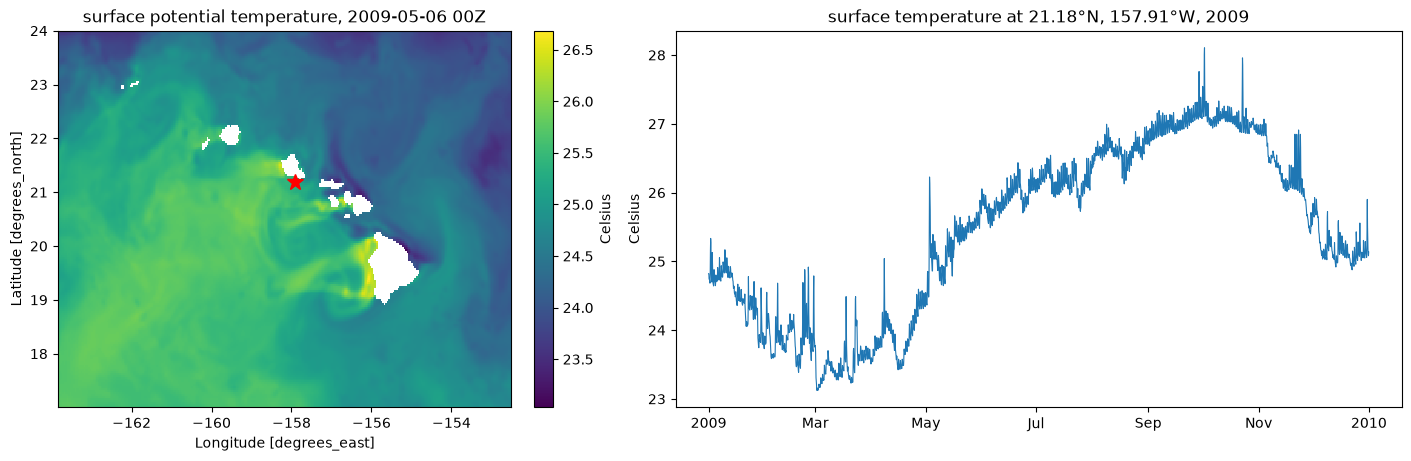

In [18]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True,
                               gridspec_kw={'width_ratios': [1, 1.6]})
sst_map.plot(ax=ax0, cmap='viridis', cbar_kwargs={'label': 'Celsius'})
ax0.plot(series.lon, series.lat, 'r*', ms=12)
ax0.set_title(f'surface potential temperature, {pd.Timestamp(sst_map.time.values):%Y-%m-%d %HZ}')
series.plot(ax=ax1, lw=0.8)
ax1.set_title(f'surface temperature at {float(series.lat):.2f}°N, {-float(series.lon):.2f}°W, 2009')
ax1.set_ylabel('Celsius')
ax1.set_xlabel('')
plt.show()

## 12. Still unknown before the production build

Reviewed 2026-11-14; the three design decisions are made (top of this notebook).

- **Full-length open and read times.** This measured one year, with one manifest per array, from
  one JupyterHub; readers elsewhere will see other rates.
  The full store has 35,040 steps, 12 manifests per array and about 5.1 M references. Measure
  open time and a 12-year point series on the scratch build.
- **Every file's layout.** 20 files were scanned and 365 inferred. Production scans all
  4,380 (about 1.6 s each, serially).
- **Remote destination and browser access.** Nothing here touched Source Cooperative's
  write side or a browser. `reanalysis-scratch-sc.ipynb` writes the same small store to a
  scratch prefix and reads it back anonymously from its public URL; a viewer is published
  beside it.

## 13. Clean up

Deletes the temporary local directory this notebook created, and nothing else.

In [19]:
assert WORK.name.startswith('pacioos-reanalysis-smoke-') and WORK.parent == Path(tempfile.gettempdir())
shutil.rmtree(WORK)
print('removed', WORK)

removed /tmp/pacioos-reanalysis-smoke-7cnomr_0
